# **01. Exploratory Data Analysis**

Tujuan notebook ini:
1. Memastikan data lengkap dan konsisten.
2. Melihat distribusi kelas.
3. Melihat contoh visual per kelas.
4. Mengukur karakteristik gambar (ukuran, mode) untuk menentukan resolusi input model.
5. Membandingkan keterbacaan dokumen pada beberapa resolusi (keputusan: ukuran cache).

In [1]:
import sys
sys.path.append("..")  # agar package scripts bisa diimpor dari folder notebooks

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

from scripts.config import Config, CLASS_NAMES
from scripts.utils import verify_data_layout

cfg = Config()
cfg.figures_dir.mkdir(parents=True, exist_ok=True)
train = pd.read_csv(cfg.train_csv)
test = pd.read_csv(cfg.test_csv)
print(train.shape, test.shape)
print(verify_data_layout(cfg))

(32003, 4) (7994, 2)
{'n_train': 32003, 'n_test': 7994, 'n_classes': 16, 'images_checked': 400}


**Interpretasi:**

Data latih berisi 32.003 baris dengan 4 kolom dan data uji 7.994 baris dengan 2 kolom, tepat sesuai deskripsi kompetisi. Pemeriksaan `verify_data_layout` lolos: label 0 sampai 15 cocok dengan nama kelas, urutan id test identik dengan `sample_submission.csv`, dan 400 file sampel ada di disk. Artinya path data benar dan format submission nanti aman. Batasannya, hanya 400 file yang dicek langsung; file rusak lainnya terdeteksi saat pembuatan cache, dan hasilnya 0 file gagal dibaca.

## 1. Distribusi kelas
Jika kelas seimbang, accuracy adalah metrik yang valid dan class weighting tidak diperlukan.

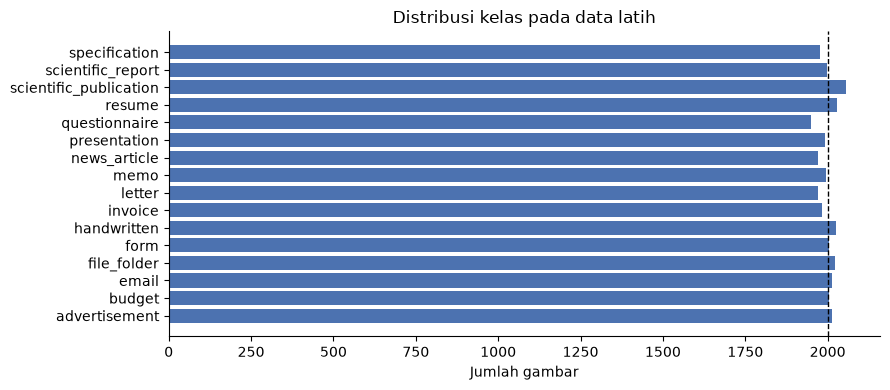

Rasio max/min: 1.055441478439425


In [2]:
counts = train["class_name"].value_counts().sort_index()
fig, ax = plt.subplots(figsize=(9, 4))
ax.barh(counts.index, counts.values, color="#4C72B0")
ax.axvline(counts.mean(), color="black", ls="--", lw=1)
ax.set_xlabel("Jumlah gambar")
ax.set_title("Distribusi kelas pada data latih")
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(cfg.figures_dir / "class_distribution.png", dpi=150)
plt.show()
print("Rasio max/min:", counts.max() / counts.min())

**Interpretasi:** 

Setiap kelas memiliki sekitar 2.000 gambar (garis putus adalah rata-rata) dengan rasio kelas terbesar terhadap terkecil 1,055. Dataset seimbang, jadi akurasi adalah metrik yang valid dan pembobotan kelas tidak diperlukan. Tebakan acak hanya benar sekitar 6,25 persen (1 dari 16), sehingga angka itu menjadi garis dasar untuk menilai model. Split validasi yang stratified akan berisi sekitar 300 gambar per kelas.

## 2. Contoh visual per kelas
Satu gambar acak per kelas, untuk memahami fitur visual pembeda (tata letak, kepadatan teks, tabel).

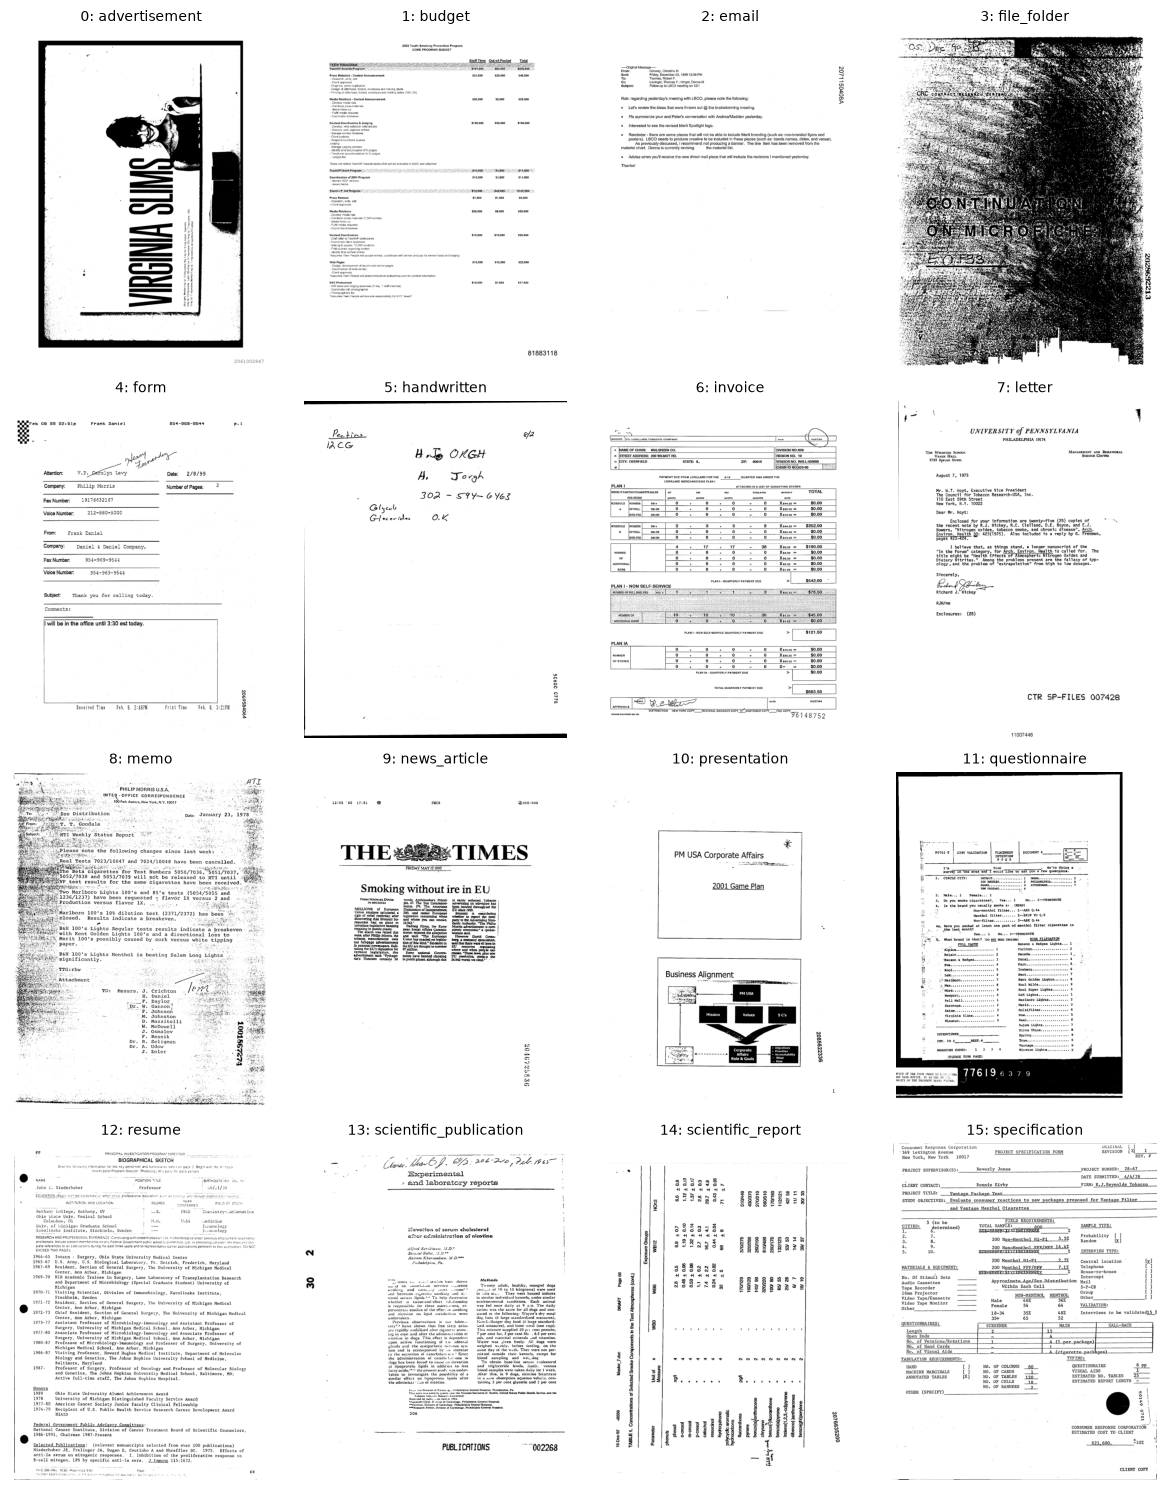

In [3]:
rng = np.random.default_rng(cfg.seed)
fig, axes = plt.subplots(4, 4, figsize=(12, 15))
for label, ax in zip(range(16), axes.ravel()):
    row = train[train["label"] == label].sample(1, random_state=int(rng.integers(1e6))).iloc[0]
    with Image.open(cfg.data_dir / row["filename"]) as im:
        ax.imshow(im.convert("L"), cmap="gray")
    ax.set_title(f"{label}: {row['class_name']}", fontsize=10)
    ax.axis("off")
plt.tight_layout()
fig.savefig(cfg.figures_dir / "samples_per_class.png", dpi=120)
plt.show()

**Interpretasi:** 

Kelas dibedakan terutama oleh tata letak, bukan oleh isi teks yang bisa dibaca pada skala ini. Advertisement didominasi gambar besar, news_article punya judul huruf besar dan kolom, presentation berupa slide dengan kotak diagram, dan email berupa blok teks pendek di bagian atas.

Kualitas scan sangat beragam: file_folder tampak gelap dan penuh derau, dan beberapa halaman memiliki bingkai hitam di tepi. Kelompok yang secara tata letak berdekatan adalah form, questionnaire, invoice, dan budget (kotak dan tabel), serta letter, memo, dan email (blok teks). Ini hipotesis awal tentang pasangan yang sulit; pengujiannya ada di notebook 02.

## 3. Karakteristik gambar
Ukuran asli dan mode warna dari sampel acak (membaca header saja, tanpa decode penuh).

mode
L    1500
Name: count, dtype: int64
         width  height   aspect
count  1500.00  1500.0  1500.00
mean    765.99  1000.0     0.77
std      20.80     0.0     0.02
min     614.00  1000.0     0.61
25%     754.00  1000.0     0.75
50%     762.00  1000.0     0.76
75%     777.00  1000.0     0.78
max     875.00  1000.0     0.88


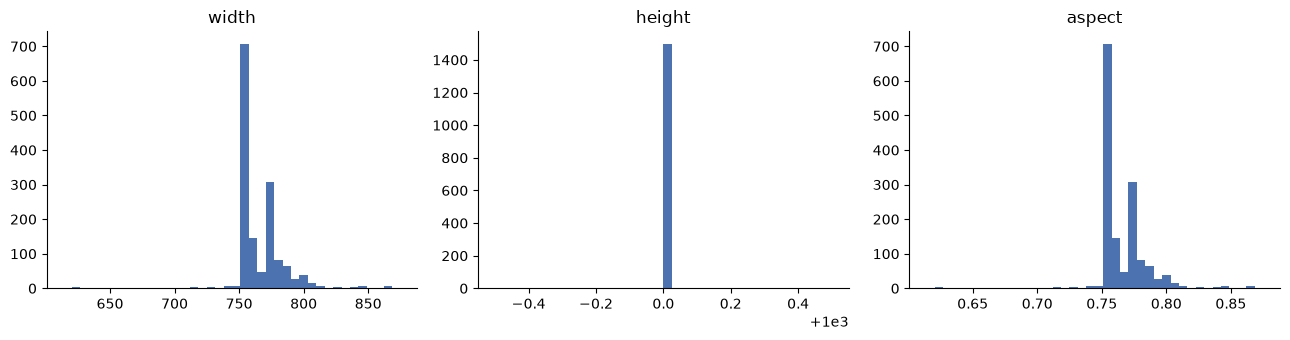

In [4]:
sample = train.sample(1500, random_state=cfg.seed)
meta = []
for rel in sample["filename"]:
    with Image.open(cfg.data_dir / rel) as im:
        meta.append((im.width, im.height, im.mode))
meta = pd.DataFrame(meta, columns=["width", "height", "mode"])
meta["aspect"] = meta["width"] / meta["height"]

print(meta["mode"].value_counts())
print(meta[["width", "height", "aspect"]].describe().round(2))

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5))
for ax, col in zip(axes, ["width", "height", "aspect"]):
    ax.hist(meta[col], bins=40, color="#4C72B0")
    ax.set_title(col)
    for s in ("top", "right"):
        ax.spines[s].set_visible(False)
plt.tight_layout()
fig.savefig(cfg.figures_dir / "image_size_distribution.png", dpi=150)
plt.show()

**Interpretasi:** 

Seluruh 1.500 sampel (4,7 persen data) berada pada mode L, yaitu grayscale, sehingga cache cukup satu channel. Tinggi gambar selalu 1.000 piksel; lebar rata-rata 766 dengan simpangan baku 21 (rentang 614 sampai 875), dan aspect ratio rata-rata 0,77 dengan simpangan baku 0,02. Histogram tinggi hanya satu batang pada 1.000 karena nilainya konstan; sumbu x yang berkisar -0,4 sampai 0,4 hanyalah artefak skala, bukan error. Karena rasionya sangat seragam, me-resize ke persegi memberi distorsi yang hampir sama untuk semua gambar sehingga tidak bias antar kelas, dan letterbox tidak diperlukan. Satu channel akan diulang tiga kali saat masuk model agar cocok dengan bobot pretrained.

## 4. Pemilihan resolusi
Satu dokumen yang sama ditampilkan pada beberapa resolusi. Pilih resolusi terkecil yang masih mempertahankan struktur tata letak (judul, kolom, tabel). Resolusi lebih kecil berarti training CPU lebih cepat.

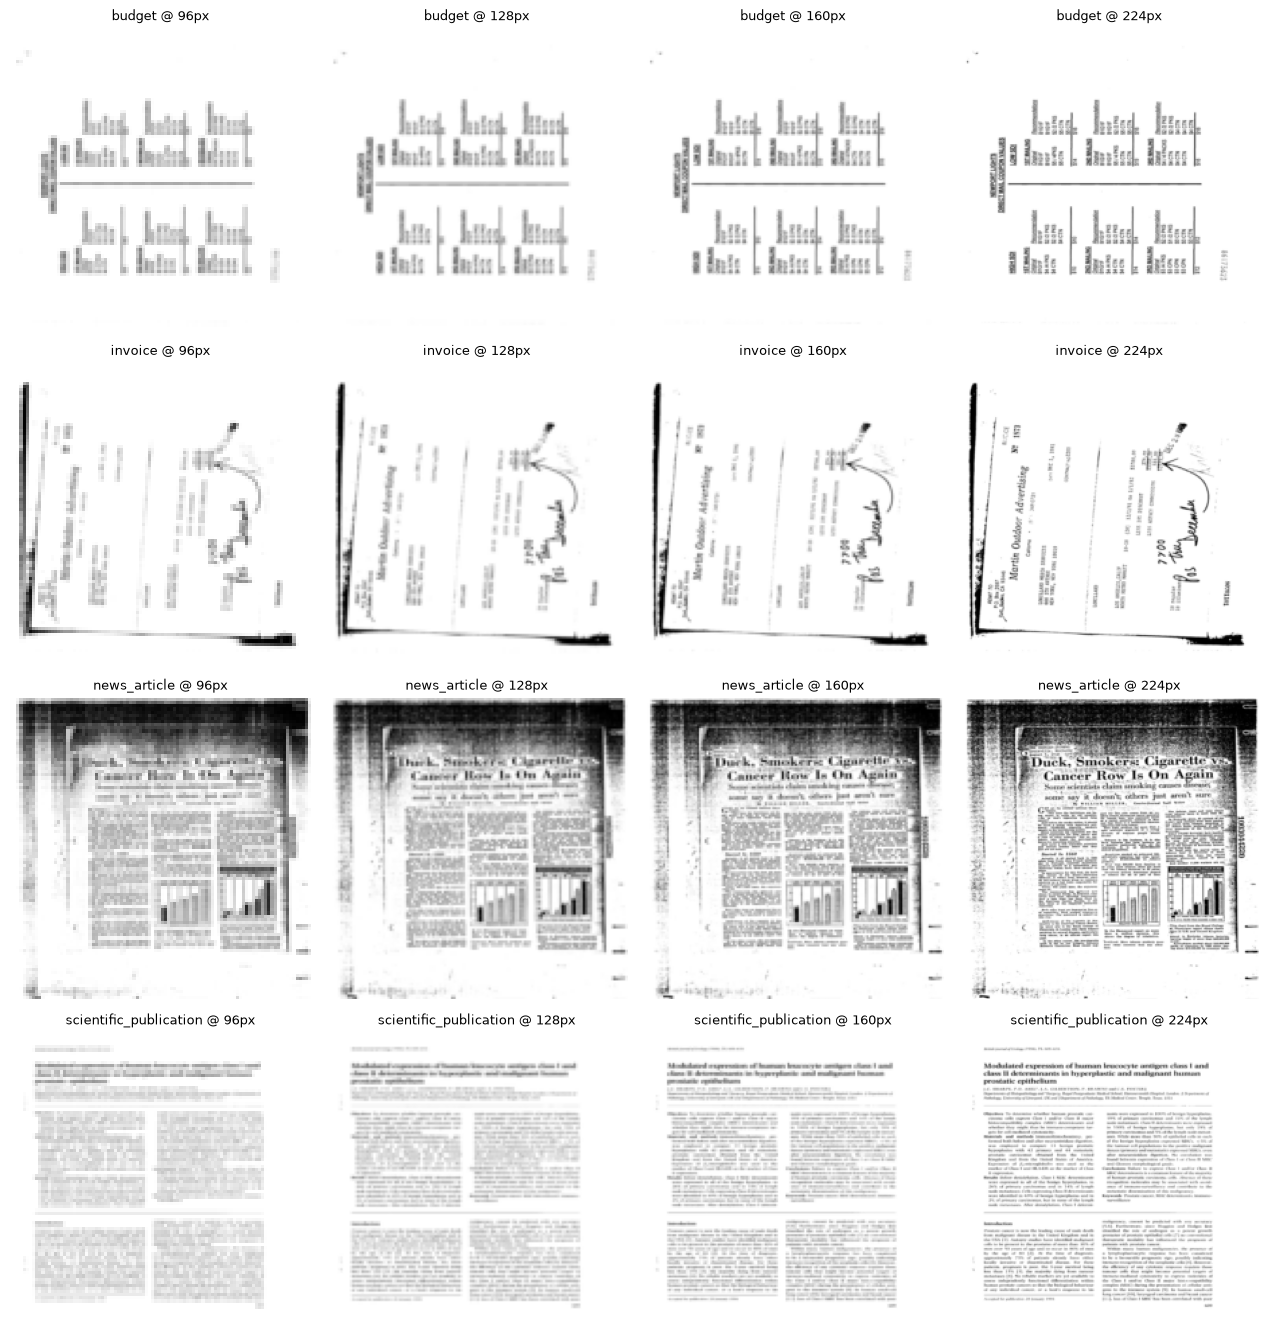

In [5]:
from scripts.preprocess import load_image

sizes = [96, 128, 160, 224]
picks = train.groupby("label").sample(1, random_state=cfg.seed).iloc[[1, 6, 9, 13]]  # budget, invoice, news, sci. publication
fig, axes = plt.subplots(len(picks), len(sizes), figsize=(3.2 * len(sizes), 3.4 * len(picks)))
for r, (_, row) in enumerate(picks.iterrows()):
    for k, s in enumerate(sizes):
        axes[r, k].imshow(load_image(cfg.data_dir / row["filename"], s), cmap="gray", vmin=0, vmax=255)
        axes[r, k].set_title(f"{row['class_name']} @ {s}px", fontsize=9)
        axes[r, k].axis("off")
plt.tight_layout()
fig.savefig(cfg.figures_dir / "resolution_comparison.png", dpi=120)
plt.show()

**Interpretasi:** 

Pada 96 piksel kolom dan baris pada scientific_publication mulai kabur; pada 160 dan 224 struktur kolom, judul, dan blok tabel terlihat jelas, sedangkan 128 berada di antaranya. Teks tidak terbaca pada resolusi mana pun, jadi model akan mengandalkan tata letak. Keputusan: 160 piksel, yang menjaga struktur dokumen dengan biaya komputasi sekitar separuh dari 224; 128 menjadi cadangan jika training terlalu lambat. Contoh budget tampak terotasi 90 derajat dan invoice sedikit miring, yang menjadi risiko bagi model berbasis tata letak dan perlu dicek saat analisis error.

## 5. Bangun cache

Jalankan dari terminal pada root repo (satu kali, beberapa menit hingga puluhan menit tergantung CPU dan disk):

```bash
python -m scripts.preprocess --size 160
```
Setelah selesai, cek bahwa tidak ada file gagal dibaca dan bentuk cache sesuai.

In [6]:
cache = np.load(cfg.cache_path("train"), mmap_mode="r")
print(cache.shape, cache.dtype)
assert cache.shape[0] == len(train)

# Intensitas rata-rata per kelas: sanity check bahwa cache selaras dengan urutan CSV
mean_intensity = pd.Series([cache[i].mean() for i in range(0, len(train), 20)],
                           index=train["class_name"].iloc[::20]).groupby(level=0).mean().sort_values()
print(mean_intensity.round(1))

(32003, 160, 160) uint8
class_name
advertisement             193.5
file_folder               199.3
scientific_publication    230.4
news_article              233.0
handwritten               235.8
scientific_report         236.7
resume                    237.2
questionnaire             238.3
invoice                   238.7
form                      239.3
presentation              239.8
budget                    239.9
specification             240.2
letter                    243.1
memo                      243.4
email                     249.5
dtype: float64


**Interpretasi:**

Cache berbentuk (32003, 160, 160) bertipe uint8, jumlah barisnya sama dengan CSV sehingga indeks cache selaras dengan baris data. Rata-rata intensitas piksel (0 hitam, 255 putih) paling rendah pada advertisement (193,5) dan file_folder (199,3), yang cocok dengan contoh visual yang gelap dan padat, dan paling tinggi pada email (249,5), halaman yang hampir putih dengan sedikit teks. Pola yang masuk akal ini menunjukkan urutan cache tidak tertukar. Perhitungannya memakai sekitar 1.600 sampel (setiap baris ke-20), jadi cukup sebagai sanity check, bukan statistik final.

## **Temuan EDA**

### 1. Distribusi Kelas
Distribusi data pada seluruh kelas relatif seimbang, dengan rasio jumlah sampel maksimum terhadap minimum sebesar 1,055. Oleh karena itu, accuracy dapat digunakan sebagai metrik evaluasi utama tanpa memerlukan pembobotan kelas (*class weighting*).

### 2. Potensi Kesalahan Klasifikasi Antar Kelas
Beberapa pasangan kelas memiliki karakteristik visual dan tata letak yang berpotensi menimbulkan kesalahan klasifikasi, yaitu *letter*, *memo*, dan *email*; *form* dan *questionnaire*; serta *scientific_publication* dan *scientific_report*. Pada kelompok pertama, intensitas piksel rata-rata berada pada kisaran 243–250. Pasangan-pasangan tersebut merupakan hipotesis awal yang perlu diuji lebih lanjut melalui *confusion matrix* setelah model dilatih dan dievaluasi; hasil pengujiannya dilaporkan di notebook 02.

### 3. Ukuran dan Rasio Aspek Gambar
Gambar memiliki tinggi 1.000 piksel dan lebar rata-rata 766 piksel, dengan rasio aspek rata-rata sekitar 0,77 serta variasi yang relatif kecil. Karakteristik ini menunjukkan bahwa gambar cenderung berorientasi potret. Oleh karena itu, perubahan ukuran menjadi dimensi persegi tanpa mempertahankan rasio aspek berpotensi menyebabkan distorsi pada struktur visual dokumen.

### 4. Penentuan Resolusi Input
Resolusi input 160 × 160 piksel dipilih sebagai kompromi antara efisiensi komputasi dan kemampuan mempertahankan karakteristik tata letak dokumen, seperti kolom dan tabel. Pada resolusi tersebut, keterbacaan teks masih terbatas. Dengan demikian, model berpotensi lebih mengandalkan pola tata letak dan karakteristik visual global dibandingkan informasi tekstual yang terperinci.

### 5. Implikasi terhadap Pemodelan
Berdasarkan karakteristik dataset, pendekatan *transfer learning* dengan arsitektur *backbone* yang relatif ringan pada resolusi input 160 × 160 piksel dapat dipertimbangkan untuk meningkatkan efisiensi pelatihan. Augmentasi data sebaiknya diterapkan secara terbatas dan tetap mempertahankan orientasi dokumen; transformasi *flip* tidak direkomendasikan karena dapat mengubah karakteristik visual yang relevan. Kelas-kelas dengan kemiripan tata letak diperkirakan menjadi sumber kesalahan klasifikasi yang perlu dianalisis melalui *confusion matrix* dan evaluasi per kelas.

## **Business Insight**

**Kualitas data memenuhi syarat untuk pemodelan**: tidak ada file rusak, label konsisten dengan nama kelas, dan kelas seimbang (rasio 1,055). Model awal (ResNet18, input 160 piksel) mencapai akurasi validasi 0,828, jauh di atas tebakan acak (0,0625), sehingga pendekatan klasifikasi berbasis tata letak layak sebagai penyortir otomatis tahap pertama.

**Kesalahan berkumpul pada kelas tertentu**: scientific_report (F1 0,623), form (0,682), dan presentation (0,717). Analisis contoh di notebook 02 menunjukkan penyebabnya tidak tunggal. Kelas scientific_report heterogen (halaman sampul, tabel, grafik, halaman judul, dan halaman teks), sehingga sebagian halamannya, terutama yang jarang teks, secara visual menyerupai slide pada resolusi 160 piksel. Sebagian kesalahan lain berasal dari dokumen yang memang bercampur ciri dua kelas atau scan yang buruk. Penyebab-penyebab ini didukung oleh sampel kecil (8 contoh per sel), sehingga masih berupa dugaan, bukan temuan yang terukur.

**Implikasi bagi pengembangan**: memperbesar model bukan prioritas, karena model sudah overfitting (selisih akurasi train dan validasi sekitar 14 poin). Opsi yang lebih masuk akal adalah regularisasi, resolusi yang lebih tinggi, atau fitur teks (OCR) untuk kelas yang pembedanya adalah isi; ketiganya belum diuji dan membutuhkan biaya komputasi lebih besar.

**Untuk penyampaian ke pihak non-teknis**: sistem ini cocok untuk mengurutkan dokumen secara otomatis dengan peninjauan manusia pada kelas berisiko error tinggi (laporan ilmiah, formulir, presentasi), bukan sebagai keputusan final tanpa pengawasan.